# Method of Moments vs. Maximum Likelihood Estimation

A visual tour connecting moment generating functions, statistical moments, and the two classic ways of fitting a distribution to data — Method of Moments (MoM) and Maximum Likelihood Estimation (MLE). We'll see where the two methods agree, where they diverge, and where moments alone stop being enough to pin down a distribution.

## Setup

All imports used throughout the notebook, gathered here once.

In [23]:
import math

import numpy as np
import scipy.integrate as integrate
import scipy.stats as stats
from scipy.optimize import minimize

import matplotlib.pyplot as plt

import plotly.graph_objects as go
from plotly.subplots import make_subplots

## Moment Generating Functions (MGFs)

Every distribution's moments can be read off its moment generating function $M(t) = E[e^{tX}]$ — its derivatives at $t=0$ give the raw moments. Below we plot the analytical MGFs of the Normal, Exponential, and Uniform distributions across a range of $t$, all anchored at $M(0)=1$.

In [24]:
# -------------------------------------------------------------------------
# 1. GENERATE CONTINUOUS PARAMETER GRID
# -------------------------------------------------------------------------
# We scan t from -0.8 to 0.8. This safe domain captures the curvature 
# without hitting the Exponential distribution's asymptote at t = 1.
t_grid = np.linspace(-0.8, 0.8, 300)

# -------------------------------------------------------------------------
# 2. COMPUTE ANALYTICAL MGF TRAJECTORIES
# -------------------------------------------------------------------------
# Normal (mean=0, std=1) -> M(t) = exp(0.5 * t^2)
y_normal = np.exp(0.5 * t_grid**2)

# Exponential (lambda=1) -> M(t) = 1 / (1 - t)
y_exponential = 1.0 / (1.0 - t_grid)

# Uniform (low=-2, high=2) -> M(t) = [exp(2t) - exp(-2t)] / (4t)
# We handle the t=0 singularity safely with np.where
y_uniform = np.where(
    t_grid == 0, 
    1.0, 
    (np.exp(2.0 * t_grid) - np.exp(-2.0 * t_grid)) / (4.0 * t_grid)
)

# -------------------------------------------------------------------------
# 3. INTERACTIVE PLOTLY RENDERING
# -------------------------------------------------------------------------
fig = go.Figure()

# Plot Normal MGF Profile
fig.add_trace(go.Scatter(
    x=t_grid, y=y_normal,
    mode='lines', line=dict(color='blue', width=2.5),
    name='Normal Distribution MGF'
))

# Plot Exponential MGF Profile
fig.add_trace(go.Scatter(
    x=t_grid, y=y_exponential,
    mode='lines', line=dict(color='red', width=2.5),
    name='Exponential Distribution MGF'
))

# Plot Uniform MGF Profile
fig.add_trace(go.Scatter(
    x=t_grid, y=y_uniform,
    mode='lines', line=dict(color='green', width=2.5),
    name='Uniform Distribution MGF'
))

# Highlight the t=0 Anchor Point
fig.add_trace(go.Scatter(
    x=[0], y=[1],
    mode='markers',
    marker=dict(color='black', size=12, symbol='circle', line=dict(width=2, color='white')),
    name='Anchor Point (t=0, M(t)=1)'
))

# -------------------------------------------------------------------------
# 4. GLOBAL INTERFACE VISUAL DESIGN
# -------------------------------------------------------------------------
fig.update_layout(
    title='Scanning Distribution Identities: How Variable t Reads the Exponents',
    xaxis_title='MGF Scanner Parameter (t)',
    yaxis_title='Calculated MGF Output',
    yaxis=dict(range=[0, 5]),
    template='plotly_white',
    width=900,
    height=550,
    hovermode='x unified'
)

# Overlay reference lines to show how the shapes diverge right out of the gate
fig.add_hline(y=1, line_dash="dash", line_color="lightgray")
fig.add_vline(x=0, line_dash="dash", line_color="lightgray")

fig.show()

## From MGF to Moments: Taylor Series Reconstruction

The MGF is also the Taylor series of $E[e^{tX}]$, so summing more moment terms should approximate it increasingly well. Using the Exponential distribution (where $M(t) = 1/(1-t)$ and every raw moment is $n!$), we compare the true integrated MGF against partial Taylor sums of increasing order to see the approximation converge.

In [25]:
# -------------------------------------------------------------------------
# 1. EVALUATION PARAMETERS
# -------------------------------------------------------------------------
# We evaluate t across a range where the MGF converges (t < 1 for Exponential with lambda=1)
t_grid = np.linspace(-0.5, 0.75, 200)

# -------------------------------------------------------------------------
# 2. COMPUTE THE TRUE CONTINUOUS MGF CURVE VIA INTEGRATION
# -------------------------------------------------------------------------
# For an Exponential distribution, M_X(t) = E[e^{tX}] = 1 / (1 - t)
y_true = np.array([integrate.quad(lambda x: np.exp((t_val - 1) * x), 0, np.inf)[0] for t_val in t_grid])

# -------------------------------------------------------------------------
# 3. CONSTRUCT INTERACTIVE HOVER CONVERGENCE CONTAINERS
# -------------------------------------------------------------------------
fig = go.Figure()

# Plot the authentic, ground-truth integration trajectory
fig.add_trace(go.Scatter(
    x=t_grid, y=y_true,
    mode='lines',
    line=dict(color='black', width=3),
    name='True MGF Integration: E[e^{tX}]'
))

# Dynamically construct higher-order Taylor approximations inside a clean loop
# For Exponential distribution, raw moments are E[X^n] = n!
# The n! terms cancel out perfectly with the Taylor denominators, leaving:
# M_X(t) = 1 + t^1 + t^2 + t^3 + ... + t^n
mom_orders = [1, 2, 4, 6]
colors = ['purple', 'orange', 'red', 'blue']

for order, color in zip(mom_orders, colors):
    # Dynamically compute the partial sums using a matrix exponent grid
    # This evaluates the vector polynomial: 1 + sum_{i=1}^{order} t^i
    y_approx = np.ones_like(t_grid)
    for i in range(1, order + 1):
        y_approx += t_grid ** i
        
    fig.add_trace(go.Scatter(
        x=t_grid, y=y_approx,
        mode='lines',
        line=dict(color=color, width=1.5, dash='dash' if order < 6 else 'solid'),
        name=f'{order}-Moment Taylor Polynomial'
    ))

# -------------------------------------------------------------------------
# 4. STRUCTURAL CANVAS DESIGN CONFIG
# -------------------------------------------------------------------------
fig.update_layout(
    title='Visualizing MGF Convergence: Reconstructing a Distribution via Exponents',
    xaxis_title='MGF Parameter (t)',
    yaxis_title='Calculated MGF Value',
    yaxis=dict(range=[0, 5]),  # Keeps the canvas tight and focuses on convergence boundaries
    template='plotly_white',
    width=900,
    height=600,
    hovermode='x unified'
)

fig.show()

## Reconstructing a PDF's Shape from Its Moments

Moments don't just describe a curve abstractly — they can be used to rebuild an approximate density via a Gram–Charlier expansion around a Normal baseline. Starting from a skewed target distribution, we layer in the 3rd (skewness) and 4th (kurtosis) standardized moments on top of a mean/variance-only Normal approximation, watching the reconstructed curve bend toward the true shape.

In [26]:
# -------------------------------------------------------------------------
# 1. GENERATE THE TRUE SKEWED PDF TARGET
# -------------------------------------------------------------------------
np.random.seed(42)
true_skew_dist = stats.skewnorm(a=5, loc=0, scale=1)
x_grid = np.linspace(-2, 4, 300)
y_true_pdf = true_skew_dist.pdf(x_grid)

# Calculate empirical moments directly from the population parameters
mu = true_skew_dist.mean()
sigma = true_skew_dist.std()
skew = stats.skewnorm.stats(a=5, moments='s')  # 3rd Standardized Moment
kurt = stats.skewnorm.stats(a=5, moments='k')  # 4th Standardized Moment (Excess)

# -------------------------------------------------------------------------
# 2. CONSTRUCT THE PDF LAYERS STEP-BY-STEP (Gram-Charlier Expansion)
# -------------------------------------------------------------------------
# Standardize the x-axis grid to get z-scores
z = (x_grid - mu) / sigma
phi = stats.norm.pdf(z) / sigma

# Baseline: 1st & 2nd Moments (Just standard mean and variance)
pdf_2_moments = phi

# Layering the 3rd Moment: Skewness introduces directional tilt
# He3(z) = z^3 - 3z
he3 = z**3 - 3*z
pdf_3_moments = phi * (1.0 + (skew / 6.0) * he3)

# Layering the 4th Moment: Kurtosis adjusts peak sharpness and tail weight
# He4(z) = z^4 - 6z^2 + 3
he4 = z**4 - 6.0*z**2 + 3.0
pdf_4_moments = phi * (1.0 + (skew / 6.0) * he3 + (kurt / 24.0) * he4)

# -------------------------------------------------------------------------
# 3. INTERACTIVE PLOTLY RENDERING
# -------------------------------------------------------------------------
fig = go.Figure()

# Ground Truth Target Curve
fig.add_trace(go.Scatter(
    x=x_grid, y=y_true_pdf,
    mode='lines', line=dict(color='black', width=3),
    name='True Target Distribution Silhouette'
))

# Mean + Variance Guess
fig.add_trace(go.Scatter(
    x=x_grid, y=pdf_2_moments,
    mode='lines', line=dict(color='blue', width=1.5, dash='dash'),
    name='1st & 2nd Moments (Mean + Variance Baseline)'
))

# Skewness Addition
fig.add_trace(go.Scatter(
    x=x_grid, y=pdf_3_moments,
    mode='lines', line=dict(color='orange', width=1.5, dash='dash'),
    name='3rd Moment Added (Skewness Asymmetry)'
))

# Full 4-Moment Custom Profile
fig.add_trace(go.Scatter(
    x=x_grid, y=pdf_4_moments,
    mode='lines', line=dict(color='red', width=2),
    name='4th Moment Added (Kurtosis Peak Correction)'
))

# Structural Canvas Design
fig.update_layout(
    title='Physically Reconstructing a PDF Shape from its Statistical Moments',
    xaxis_title='Value (x)',
    yaxis_title='Probability Density',
    template='plotly_white',
    width=950, height=600,
    hovermode='x unified'
)

fig.show()

## Method of Moments vs. MLE: Large Samples

With plenty of data, Method of Moments (matching sample moments to distributional moments) and Maximum Likelihood Estimation (maximizing the likelihood of the observed data) tend to agree closely. Here we fit both estimators to $N=500$ samples from Normal, Exponential, Gamma, and Uniform distributions and compare the resulting fits.

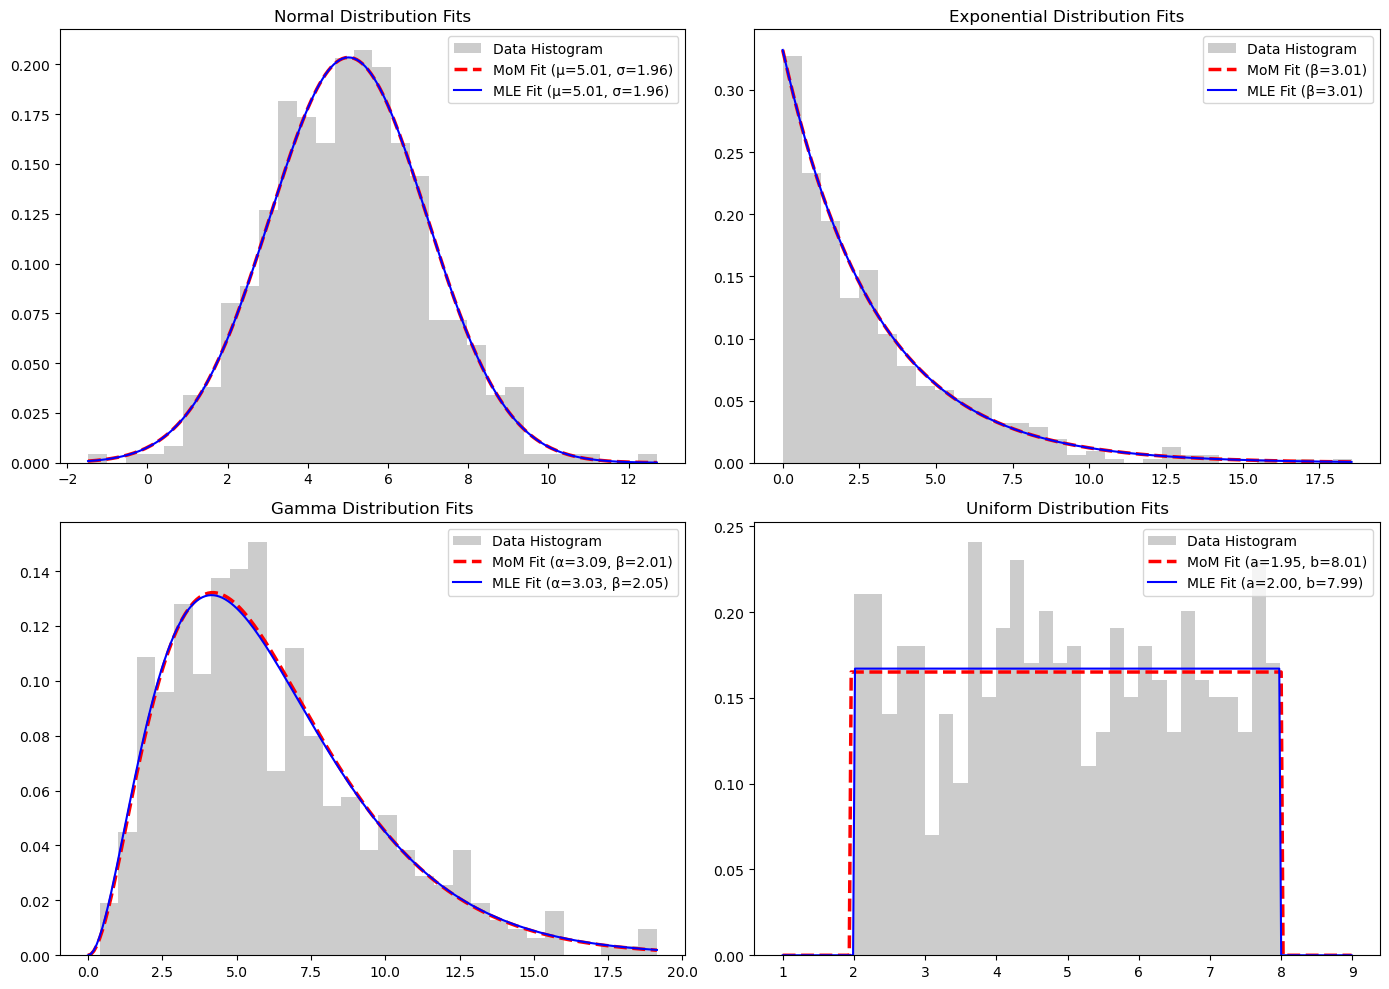

In [27]:
# Set random seed for reproducible sample datasets
np.random.seed(42)
N = 500  # Sample size (smaller size highlights the difference between MoM and MLE)

# -------------------------------------------------------------------------
# 1. Define True Parameters and Generate 4 Sample Datasets
# -------------------------------------------------------------------------
# Normal(mean=5, std=2)
data_normal = np.random.normal(loc=5.0, scale=2.0, size=N)

# Exponential(scale = 1/lambda = 3.0 -> lambda = 0.333)
data_exponential = np.random.exponential(scale=3.0, size=N)

# Gamma(shape=3.0, scale=2.0)
data_gamma = np.random.gamma(shape=3.0, scale=2.0, size=N)

# Uniform(low=2.0, high=8.0)
data_uniform = np.random.uniform(low=2.0, high=8.0, size=N)

# -------------------------------------------------------------------------
# 2. Set up Matplotlib 2x2 Subplots Grid
# -------------------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

# -------------------------------------------------------------------------
# Subplot 1: Normal Distribution
# -------------------------------------------------------------------------
ax = axes[0]
sample_mean = np.mean(data_normal)
sample_var = np.var(data_normal)

# Estimations (For Normal, MoM and MLE algebraic solutions happen to be identical)
mom_mu, mom_std = sample_mean, np.sqrt(sample_var)
mle_mu, mle_std = stats.norm.fit(data_normal)

# Plotting
x = np.linspace(min(data_normal), max(data_normal), 200)
ax.hist(data_normal, bins=30, density=True, alpha=0.4, color='gray', label='Data Histogram')
ax.plot(x, stats.norm.pdf(x, mom_mu, mom_std), 'r--', lw=2.5, label=f'MoM Fit (μ={mom_mu:.2f}, σ={mom_std:.2f})')
ax.plot(x, stats.norm.pdf(x, mle_mu, mle_std), 'b-', lw=1.5, label=f'MLE Fit (μ={mle_mu:.2f}, σ={mle_std:.2f})')
ax.set_title("Normal Distribution Fits")
ax.legend()

# -------------------------------------------------------------------------
# Subplot 2: Exponential Distribution
# -------------------------------------------------------------------------
ax = axes[1]
sample_mean = np.mean(data_exponential)

# Estimations
mom_scale = sample_mean  # MoM: beta = mean
# MLE via scipy fixes location parameter at 0
mle_loc, mle_scale = stats.expon.fit(data_exponential, floc=0) 

# Plotting
x = np.linspace(0, max(data_exponential), 200)
ax.hist(data_exponential, bins=30, density=True, alpha=0.4, color='gray', label='Data Histogram')
ax.plot(x, stats.expon.pdf(x, scale=mom_scale), 'r--', lw=2.5, label=f'MoM Fit (β={mom_scale:.2f})')
ax.plot(x, stats.expon.pdf(x, scale=mle_scale), 'b-', lw=1.5, label=f'MLE Fit (β={mle_scale:.2f})')
ax.set_title("Exponential Distribution Fits")
ax.legend()

# -------------------------------------------------------------------------
# Subplot 3: Gamma Distribution
# -------------------------------------------------------------------------
ax = axes[2]
sample_mean = np.mean(data_gamma)
sample_var = np.var(data_gamma)

# Estimations
mom_alpha = (sample_mean ** 2) / sample_var
mom_beta = sample_var / sample_mean
mle_alpha, mle_loc, mle_beta = stats.gamma.fit(data_gamma, floc=0)

# Plotting
x = np.linspace(0, max(data_gamma), 200)
ax.hist(data_gamma, bins=30, density=True, alpha=0.4, color='gray', label='Data Histogram')
ax.plot(x, stats.gamma.pdf(x, a=mom_alpha, scale=mom_beta), 'r--', lw=2.5, label=f'MoM Fit (α={mom_alpha:.2f}, β={mom_beta:.2f})')
ax.plot(x, stats.gamma.pdf(x, a=mle_alpha, scale=mle_beta), 'b-', lw=1.5, label=f'MLE Fit (α={mle_alpha:.2f}, β={mle_beta:.2f})')
ax.set_title("Gamma Distribution Fits")
ax.legend()

# -------------------------------------------------------------------------
# Subplot 4: Uniform Distribution (Crucial visual difference)
# -------------------------------------------------------------------------
ax = axes[3]
sample_mean = np.mean(data_uniform)
sample_var = np.var(data_uniform)

# Estimations
# MoM uses the mean and variance math formulas to estimate boundaries
mom_a = sample_mean - np.sqrt(3 * sample_var)
mom_b = sample_mean + np.sqrt(3 * sample_var)

# MLE optimization dictates boundaries must match sample minimum and maximum points
mle_loc, mle_scale = stats.uniform.fit(data_uniform)
mle_a = mle_loc
mle_b = mle_loc + mle_scale

# Plotting
x = np.linspace(min(data_uniform) - 1, max(data_uniform) + 1, 300)
ax.hist(data_uniform, bins=30, density=True, alpha=0.4, color='gray', label='Data Histogram')
ax.plot(x, stats.uniform.pdf(x, loc=mom_a, scale=mom_b - mom_a), 'r--', lw=2.5, label=f'MoM Fit (a={mom_a:.2f}, b={mom_b:.2f})')
ax.plot(x, stats.uniform.pdf(x, loc=mle_a, scale=mle_b - mle_a), 'b-', lw=1.5, label=f'MLE Fit (a={mle_a:.2f}, b={mle_b:.2f})')
ax.set_title("Uniform Distribution Fits")
ax.legend()

# Final layout adjustments
plt.tight_layout()
plt.show()

## Method of Moments vs. MLE: Small Samples and Corrupted Data

The two estimators can diverge sharply once samples are small or contain awkward points. With only $N=35$ samples — plus an added left-shift on the Exponential data and a single large outlier in the Uniform data — MoM and MLE produce visibly different fits. This matters most for Gamma (a free MLE location parameter vs. a fixed-location MoM) and Uniform (MLE anchors to the sample min/max, so one outlier drags its whole support).

In [28]:
# Set random seed for reproducible sampling errors
np.random.seed(101)
N = 35

# -------------------------------------------------------------------------
# GLOBAL PLOTLY TRACE GENERATOR
# -------------------------------------------------------------------------
def add_subplot_traces(fig, row, col, data, x_grid, pdf_mom, pdf_mle):
    """Abstracts common Plotly histogram and line rendering to avoid repetition."""
    is_first = (row == 1 and col == 1)
    fig.add_trace(go.Histogram(x=data, histnorm='probability density', marker_color='gray', opacity=0.4, showlegend=is_first, name="Data"), row=row, col=col)
    fig.add_trace(go.Scatter(x=x_grid, y=pdf_mom, line=dict(color='red', width=2.5, dash='dash'), showlegend=is_first, name="MoM Fit"), row=row, col=col)
    fig.add_trace(go.Scatter(x=x_grid, y=pdf_mle, line=dict(color='blue', width=1.5), showlegend=is_first, name="MLE Fit"), row=row, col=col)

# -------------------------------------------------------------------------
# 1. GENERATE EXPERIMENTAL DATASETS
# -------------------------------------------------------------------------
data_normal = np.random.normal(loc=5.0, scale=2.0, size=N)
data_exponential = np.random.exponential(scale=3.0, size=N) + 1.5 # Shifted baseline
data_gamma = np.random.gamma(shape=2.0, scale=2.0, size=N)
data_uniform = np.append(np.random.uniform(low=2.0, high=8.0, size=N), [16.5]) # Massive outlier

fig = make_subplots(
    rows=2, cols=2, 
    subplot_titles=(
        "Normal (Small Sample Shift)", 
        "Exponential (With Left-Shift Boundary)", 
        "Gamma (3-Param MLE vs 2-Param MoM)", 
        "Uniform (Massive Outlier Visual Fracture)"
    )
)

# -------------------------------------------------------------------------
# SUBPLOT 1: NORMAL DISTRIBUTION
# -------------------------------------------------------------------------
d = data_normal
x = np.linspace(min(d)-1, max(d)+1, 200)

mu_mom, std_mom = np.mean(d), np.sqrt(np.var(d))
mu_mle, std_mle = np.mean(d), np.sqrt(np.var(d))

pdf_mom = (1 / (std_mom * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((x - mu_mom) / std_mom) ** 2)
pdf_mle = (1 / (std_mle * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((x - mu_mle) / std_mle) ** 2)

add_subplot_traces(fig, 1, 1, d, x, pdf_mom, pdf_mle)

# -------------------------------------------------------------------------
# SUBPLOT 2: EXPONENTIAL DISTRIBUTION
# -------------------------------------------------------------------------
d = data_exponential
x = np.linspace(0, max(d)+1, 200)

scale_mom = np.mean(d)
loc_mle = np.min(d)
scale_mle = np.mean(d) - loc_mle

pdf_mom = np.array([(1 / scale_mom) * np.exp(-xi / scale_mom) if xi >= 0 else 0 for xi in x])
pdf_mle = np.array([(1 / scale_mle) * np.exp(-(xi - loc_mle) / scale_mle) if xi >= loc_mle else 0 for xi in x])

add_subplot_traces(fig, 1, 2, d, x, pdf_mom, pdf_mle)

# -------------------------------------------------------------------------
# SUBPLOT 3: GAMMA DISTRIBUTION
# -------------------------------------------------------------------------
d = data_gamma
x = np.linspace(0.1, max(d)+1, 200)

mean, var = np.mean(d), np.var(d)
alpha_mom = (mean ** 2) / var
beta_mom = var / mean

def gamma_nll(params):
    a, loc, b = params
    if a <= 0 or b <= 0 or np.any(d <= loc): return 1e10
    return -np.sum((a-1)*np.log(d-loc) - (d-loc)/b - a*np.log(b) - np.log(np.float64(math.gamma(a))))

res = minimize(gamma_nll, [2.0, 0.0, 2.0], method='Nelder-Mead')
alpha_mle, loc_mle, beta_mle = res.x

pdf_mom = (x**(alpha_mom-1) * np.exp(-x/beta_mom)) / (beta_mom**alpha_mom * math.gamma(alpha_mom))
pdf_mle = np.array([((xi-loc_mle)**(alpha_mle-1) * np.exp(-(xi-loc_mle)/beta_mle)) / (beta_mle**alpha_mle * math.gamma(alpha_mle)) if xi > loc_mle else 0 for xi in x])

add_subplot_traces(fig, 2, 1, d, x, pdf_mom, pdf_mle)

# -------------------------------------------------------------------------
# SUBPLOT 4: UNIFORM DISTRIBUTION
# -------------------------------------------------------------------------
d = data_uniform
x = np.linspace(0, 18, 300)

mean, var = np.mean(d), np.var(d)
a_mom = mean - np.sqrt(3 * var)
b_mom = mean + np.sqrt(3 * var)

a_mle = np.min(d)
b_mle = np.max(d)

pdf_mom = np.where((x >= a_mom) & (x <= b_mom), 1 / (b_mom - a_mom), 0)
pdf_mle = np.where((x >= a_mle) & (x <= b_mle), 1 / (b_mle - a_mle), 0)

add_subplot_traces(fig, 2, 2, d, x, pdf_mom, pdf_mle)

# -------------------------------------------------------------------------
# GLOBAL INTERFACE LAYOUT CONFIG
# -------------------------------------------------------------------------
fig.update_layout(
    title_text="Empirical Silhouette Splitting: MoM vs Manual MLE",
    template="plotly_white",
    width=1100,
    height=800,
    hovermode="x unified"
)

fig.show()

## The Hamburger Moment Problem: When Moments Aren't Enough

Matching moments assumes moments uniquely determine a distribution — but that's not always true. This is the classical Hamburger moment problem: some distributions share every moment yet have completely different shapes. We build a "wavy twin" of the Log-Normal distribution whose moments match the base distribution to high order, then show its PDF is visually distinct and that its moment-generating function's Taylor sum actually diverges rather than converging to a shared MGF.

In [29]:
# -------------------------------------------------------------------------
# 1. DISTRIBUTION DEFINITIONS
# -------------------------------------------------------------------------
def f_0(x):
    """Standard Log-Normal PDF with safe vectorized support handling."""
    x_arr = np.asarray(x, dtype=float)
    pdf = np.zeros_like(x_arr)
    pos = x_arr > 0
    pdf[pos] = (1.0 / (x_arr[pos] * np.sqrt(2.0 * np.pi))) * np.exp(- (np.log(x_arr[pos])**2) / 2.0)
    return pdf if pdf.ndim > 0 else pdf.item()

def f_a(x, a=0.5):
    """Wavy Log-Normal Twin (Identical moments, distinct silhouette)."""
    x_arr = np.asarray(x, dtype=float)
    return f_0(x_arr) * (1.0 + a * np.sin(2.0 * np.pi * np.log(np.where(x_arr > 0, x_arr, 1.0))))

# -------------------------------------------------------------------------
# 2. COMPUTE FINITE MOMENTS AND ACCUMULATE PARTIAL MGF SUMS
# -------------------------------------------------------------------------
orders = np.arange(1, 11)
moments_base = []
moments_twin = []

t = 0.05  # Small scaling variable for MGF evaluation
mgf_sums_base = [1.0]
mgf_sums_twin = [1.0]

for n in orders:
    m_base = float(np.exp((n**2) / 2.0))
    
    # Integrating in z-space: z = ln(x) - n
    # The integrand is strictly odd, yielding ~0 without roundoff blowup
    perturbation, _ = integrate.quad(
        lambda z: np.exp(-0.5 * z**2) * np.sin(2.0 * np.pi * z),
        -8, 8
    )
    perturbation *= (0.5 * m_base / np.sqrt(2.0 * np.pi))
    m_twin = m_base + perturbation
    
    moments_base.append(m_base)
    moments_twin.append(m_twin)
    
    term_base = (t**n / math.factorial(n)) * m_base
    term_twin = (t**n / math.factorial(n)) * m_twin
    
    mgf_sums_base.append(mgf_sums_base[-1] + term_base)
    mgf_sums_twin.append(mgf_sums_twin[-1] + term_twin)

# -------------------------------------------------------------------------
# 3. INTERACTIVE PLOTLY VISUALIZATION (2x2 GRID)
# -------------------------------------------------------------------------
fig = make_subplots(
    rows=2, cols=2, 
    subplot_titles=(
        "Standard Log-Normal Density Function f_0(x)", 
        "Wavy Twin Density Function f_a(x)",
        "Moment Parity Plot (Log-Log Scale)", 
        "MGF Taylor Series Partial Sum Explosion"
    )
)

x_grid = np.linspace(0.01, 5.0, 500)
y_base_pdf = f_0(x_grid)
y_twin_pdf = f_a(x_grid)

# --- Top Row: Probability Density Functions ---
fig.add_trace(go.Scatter(
    x=x_grid, y=y_base_pdf,
    mode='lines', line=dict(color='blue', width=2),
    name='Base Log-Normal'
), row=1, col=1)

fig.add_trace(go.Scatter(
    x=x_grid, y=y_twin_pdf,
    mode='lines', line=dict(color='red', width=2, dash='dash'),
    name='Wavy Twin (a=0.5)'
), row=1, col=2)

# --- Bottom Left: Direct Moment Comparison ---
fig.add_trace(go.Scatter(
    x=moments_base, y=moments_twin,
    mode='markers+lines',
    marker=dict(color='purple', size=8),
    line=dict(color='purple', width=1.5),
    name='Moment Value Matches'
), row=2, col=1)

min_val, max_val = min(moments_base), max(moments_base)
fig.add_trace(go.Scatter(
    x=[min_val, max_val], y=[min_val, max_val],
    mode='lines', line=dict(color='black', dash='dash', width=1),
    name='Perfect Identity (Y = X)'
), row=2, col=1)

# --- Bottom Right: MGF Partial Sum Divergence ---
iterations = np.arange(0, len(mgf_sums_base))
fig.add_trace(go.Scatter(
    x=iterations, y=mgf_sums_base,
    mode='lines+markers', line=dict(color='blue', width=2),
    name='Base MGF Sum'
), row=2, col=2)

fig.add_trace(go.Scatter(
    x=iterations, y=mgf_sums_twin,
    mode='lines+markers', line=dict(color='red', width=2, dash='dash'),
    name='Wavy Twin MGF Sum'
), row=2, col=2)

fig.update_layout(
    title_text="The Failure of Convergence: Unveiling the Hamburger Moment Problem",
    template="plotly_white",
    width=1100, height=900,
    hovermode="x unified"
)

fig.update_xaxes(title_text="x", row=1, col=1)
fig.update_yaxes(title_text="Probability Density", row=1, col=1)
fig.update_xaxes(title_text="x", row=1, col=2)
fig.update_yaxes(title_text="Probability Density", row=1, col=2)

fig.update_xaxes(title_text="Base Log-Normal Moments", type="log", row=2, col=1)
fig.update_yaxes(title_text="Wavy Twin Moments", type="log", row=2, col=1)

fig.update_xaxes(title_text="Number of Moments Added to Sum", row=2, col=2)
fig.update_yaxes(title_text="Calculated MGF Value", type="log", row=2, col=2)

fig.show()